# Notebook 4 — Explainability | Protein Source Recognition (low-memory version)

Notebook 3 answered how accurately the models recognize the five proteins. Here, I want to know **what they are actually looking at**. I'm keeping the analysis practical: inspect correct predictions, inspect mistakes, compare all three models on the same image, and test whether the black padding from Notebook 2 is a shortcut.

**Memory strategy:** I load **one model at a time**, reuse Notebook 3's saved test predictions, and release TensorFlow and the explainability helper's model cache between models. The original 0–255 test images stay memory-mapped on disk. There is no training or augmentation here.

## 1. Load the saved test set and classifier results

I'm using exactly the same test set and class labels as Notebook 3. I don't need to load all the pretrained backbones just to decide which images were classified correctly. Notebook 3 already saved those predictions. This should avoid repeating a lot of inference.

In [1]:
from pathlib import Path
import gc, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import accuracy_score
from IPython.display import display

# Professor's unmodified module: image_explainers.py must be beside this notebook.
HERE = Path.cwd().resolve()
REPO = HERE.parent if HERE.name == "notebooks" else HERE
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
if str(REPO / "notebooks") not in sys.path:
    sys.path.insert(0, str(REPO / "notebooks"))
import image_explainers as xai

DATA_DIR = Path.home() / "MSDS565_data" / "P2_processed"
MODELS_DIR = REPO / "models"
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r")
y_test = np.load(DATA_DIR / "y_test.npy")
map_path = MODELS_DIR / "label_mapping.json"
if not map_path.exists():
    map_path = DATA_DIR / "label_mapping.json"
label_to_index = json.loads(map_path.read_text())
class_names = [name for name, idx in sorted(label_to_index.items(), key=lambda kv: kv[1])]

MODEL_KEYS = ("mobilenetv2", "resnet50", "efficientnetv2m")
BUILDERS = {
    "mobilenetv2": keras.applications.MobileNetV2,
    "resnet50": keras.applications.ResNet50,
    "efficientnetv2m": keras.applications.EfficientNetV2M,
}
missing = [str(p) for key in MODEL_KEYS for p in (
    MODELS_DIR / f"P2_N3_{key}.keras",
    MODELS_DIR / f"P2_N3_{key}_predictions.npy") if not p.exists()]
if missing:
    raise FileNotFoundError("Missing Notebook 3 outputs:\n" + "\n".join(missing))

preds_by_model = {k: np.load(MODELS_DIR / f"P2_N3_{k}_predictions.npy") for k in MODEL_KEYS}
for k, preds in preds_by_model.items():
    assert len(preds) == len(y_test), f"Wrong prediction count for {k}"
print("Test data:", X_test.shape, "| Classes:", class_names)
print("Saved test accuracies:", {k: round(float(accuracy_score(y_test,p)), 3) for k,p in preds_by_model.items()})
print("Only test arrays and small saved predictions loaded; no neural networks yet.")

2026-11-17 23:17:29.555370: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Test data: (314, 224, 224, 3) | Classes: ['beef', 'chicken', 'salmon', 'shrimp', 'tofu']
Saved test accuracies: {'mobilenetv2': 0.825, 'resnet50': 0.857, 'efficientnetv2m': 0.854}
Only test arrays and small saved predictions loaded; no neural networks yet.


## 2. Select examples without cherry-picking

I pick **three correct predictions across three different protein classes**, plus **three errors**, from MobileNetV2. I'm using the small model here on purpose: it gives me meaningful examples without needing to keep a much larger backbone in memory. I can still compare **all three** architectures using one shared photo later.

In [2]:
REFERENCE = "mobilenetv2"  # Smallest model for repeated explanation maps
pred = preds_by_model[REFERENCE]
correct_idx = np.flatnonzero(pred == y_test)
wrong_idx = np.flatnonzero(pred != y_test)
correct_three = []
for idx in correct_idx:
    if y_test[idx] not in [y_test[j] for j in correct_three]:
        correct_three.append(int(idx))
    if len(correct_three) == 3:
        break
wrong_three = list(map(int, wrong_idx[:3]))
if len(correct_three) < 3 or len(wrong_three) < 3:
    raise RuntimeError("Not enough different-class correct examples or errors; select a different reference model.")
shared_idx = correct_three[0]
print("Three correct indices:", correct_three, "| Classes:", [class_names[int(y_test[i])] for i in correct_three])
print("Three incorrect indices:", wrong_three)
print("Shared comparison index:", shared_idx)

Three correct indices: [0, 2, 3] | Classes: ['beef', 'shrimp', 'tofu']
Three incorrect indices: [4, 5, 7]
Shared comparison index: 0


## 3. Build one joined model at a time

These are the **same ImageNet applications and saved Dense softmax probes** from Notebook 3. The backbones remain frozen. The professor's `image_explainers.py` handles the correct preprocessing, so I'm sending it the original raw 0–255 images, not pre-scaled arrays.

One detail that matters for memory: the helper caches references to joined models. I clear that cache after each model and release the TensorFlow session so the large models don't pile up.

In [3]:
def load_joined(name):
    base = BUILDERS[name](
        weights="imagenet", include_top=False, pooling="avg",
        input_shape=(224, 224, 3)
    )
    base.trainable = False
    probe = keras.models.load_model(MODELS_DIR / f"P2_N3_{name}.keras", compile=False)
    joined = keras.Sequential([keras.Input((224,224,3)), base, probe], name=f"joined_{name}")
    return joined


def release_model():
    # image_explainers retains its own strong references; clear them explicitly.
    xai._parts_cache.clear()
    keras.backend.clear_session()
    gc.collect()


def smoothgrad_32_low_memory(model, img):
    """32 total noisy samples, computed 4 at a time via the provided helper.

    Averages 8 maps of 4 noisy images each, reducing peak memory. Note
    that per-chunk channel maxima make this an approximation to a single
    xai.saliency(model, img, smooth=32) call.
    """
    pred_class = int(np.argmax(xai.predict_proba(model, img)))
    total = np.zeros(img.shape[:2], dtype=np.float64)
    for _ in range(8):
        total += xai.saliency(model, img, smooth=4, class_index=pred_class)
    return (total / 8).astype(np.float32)


def show_explanation(model, img, title):
    probs = xai.predict_proba(model, img)
    predicted = int(np.argmax(probs))
    raw = xai.saliency(model, img, class_index=predicted)
    smooth = (xai.saliency(model, img, smooth=32, class_index=predicted)
              if model.name.endswith("mobilenetv2") else smoothgrad_32_low_memory(model, img))
    cam = xai.grad_cam(model, img, class_index=predicted)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
    axes[0].imshow(img)
    axes[0].set_title("Input")
    for ax, heat, label in zip(axes[1:], (raw,smooth,cam), ("Raw saliency","SmoothGrad (32)","Grad-CAM")):
        ax.imshow(xai.overlay(img, heat))
        ax.set_title(label)
    for ax in axes: ax.axis("off")
    fig.suptitle(f"{title} | predicted: {class_names[predicted]} ({probs[predicted]:.2f})", fontsize=10)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    del raw, smooth, cam, probs
    gc.collect()

## 4. Explain three correct predictions and three errors

The raw saliency tends to be speckled because it's sensitive to individual pixels. SmoothGrad uses **32 noisy samples**. For MobileNetV2 I use the professor’s exact `smooth=32` call. For the larger models I approximate this with eight smaller four-sample runs to reduce peak memory, and I would not claim those maps are numerically identical. Grad-CAM is coarser and tells me which *region* matters, not which specific pixels.

I'm particularly interested in whether the model focuses on the food or gets distracted by the plate, hands, background, or the padding we added in Notebook 2.

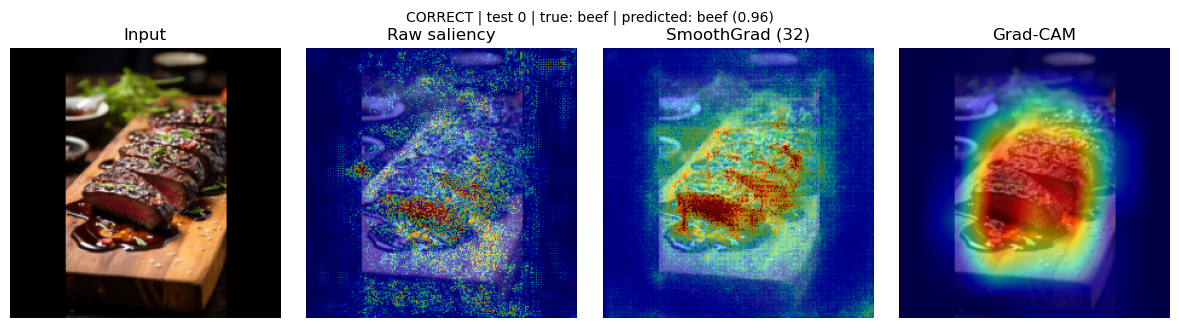

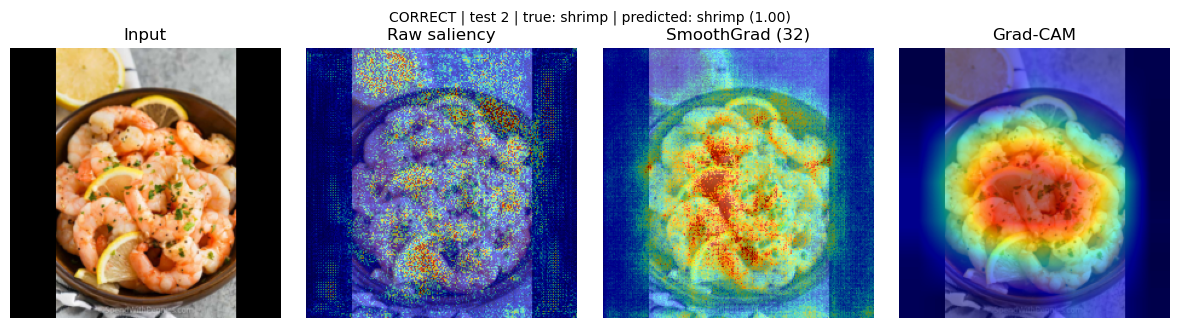

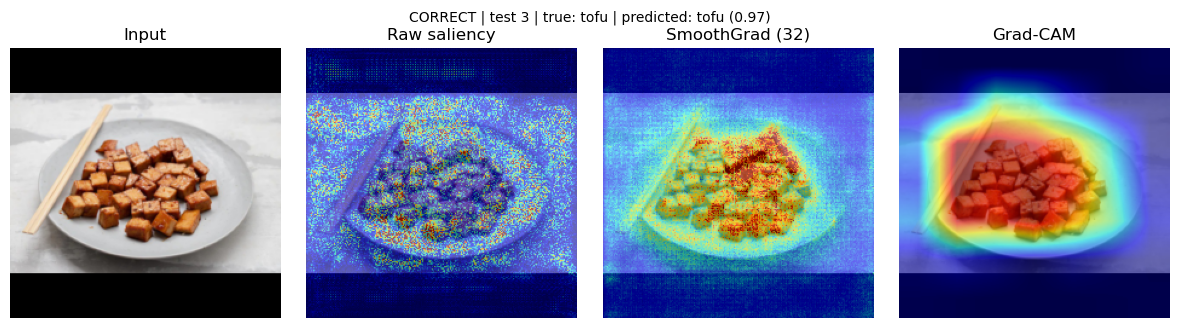

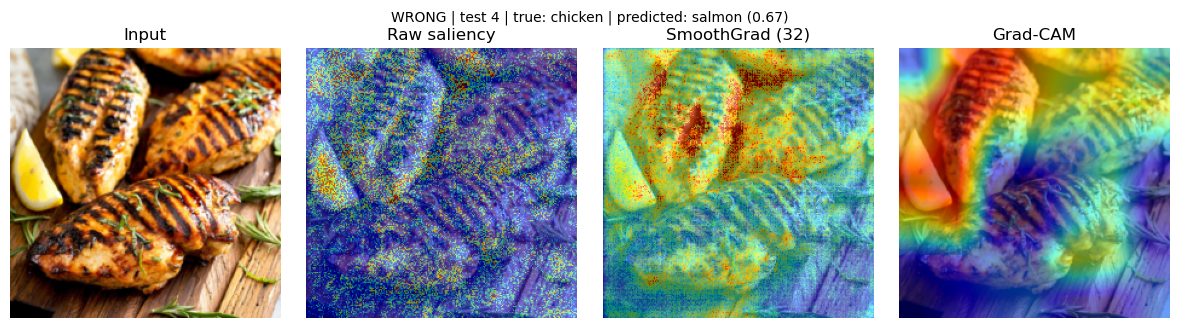

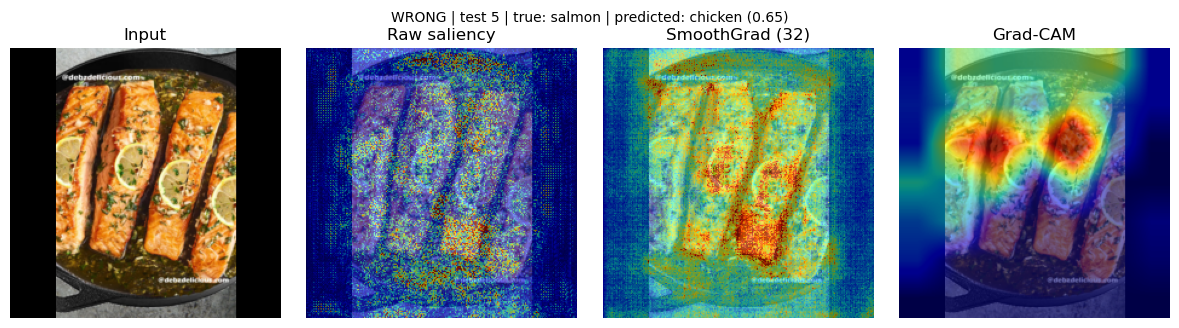

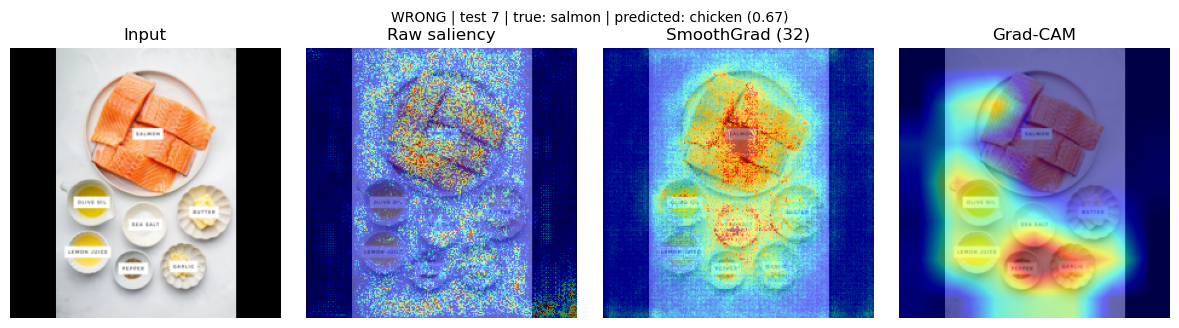

Finished six example explanations with mobilenetv2


In [4]:
model = None
try:
    model = load_joined(REFERENCE)
    for idx in correct_three:
        img = np.array(X_test[idx], copy=True)
        show_explanation(model, img, f"CORRECT | test {idx} | true: {class_names[int(y_test[idx])]}")
        del img
    for idx in wrong_three:
        img = np.array(X_test[idx], copy=True)
        show_explanation(model, img, f"WRONG | test {idx} | true: {class_names[int(y_test[idx])]}")
        del img
finally:
    del model
    release_model()
print("Finished six example explanations with", REFERENCE)

## 5. Compare the same photo across all three pretrained models

This is the model-size comparison from Notebook 3, but in visual form. The same protein photo goes through all three models. I want to see whether the bigger model actually identifies the food region better, instead of just producing a slightly different accuracy score.

**Memory precaution:** these are separate model runs, not three models held in RAM. I also report the feature-map grid used by each model's Grad-CAM, before it gets enlarged to the image size.


mobilenetv2 | saved prediction: beef
Native Grad-CAM feature grid: (7, 7)


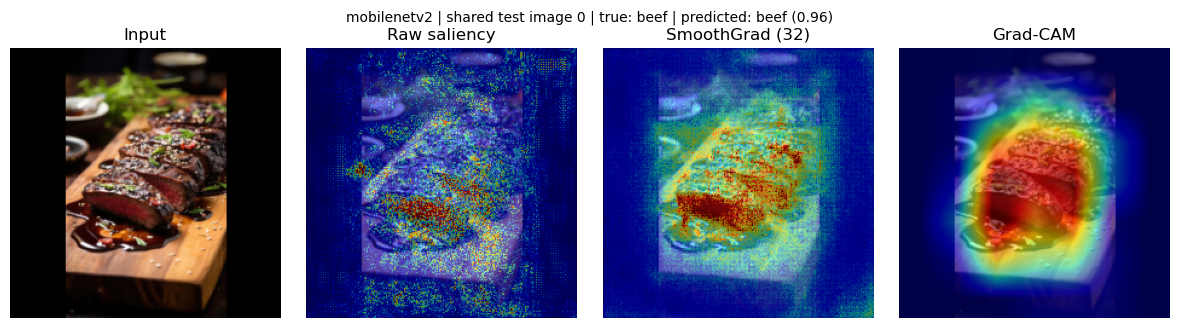


resnet50 | saved prediction: beef
Native Grad-CAM feature grid: (7, 7)


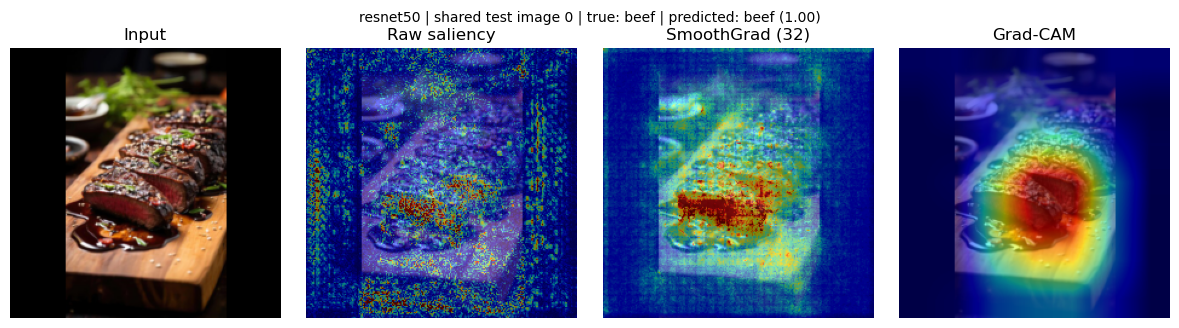


efficientnetv2m | saved prediction: beef
Native Grad-CAM feature grid: (7, 7)


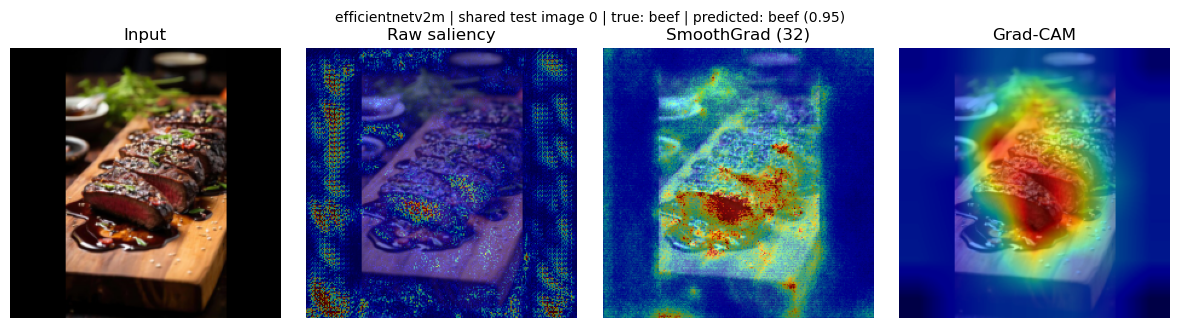

All three backbones compared; none retained in memory.


In [5]:
for name in MODEL_KEYS:
    model = None
    try:
        print(f"\n{name} | saved prediction: {class_names[int(preds_by_model[name][shared_idx])]}", flush=True)
        model = load_joined(name)
        base = model.layers[0]
        map_layers = [layer for layer in base.layers
                      if not isinstance(layer, keras.layers.InputLayer)
                      and len(layer.output.shape) == 4]
        print("Native Grad-CAM feature grid:", tuple(map_layers[-1].output.shape[1:3]))
        img = np.array(X_test[shared_idx], copy=True)
        show_explanation(model, img, f"{name} | shared test image {shared_idx} | true: {class_names[int(y_test[shared_idx])]}")
        del img
    finally:
        del model
        release_model()
print("All three backbones compared; none retained in memory.")

## 6. Shortcut hunt — does the black padding change predictions?

The black borders are a side effect of the aspect-ratio-preserving resize in Notebook 2. To check whether the model relies on that artifact, I **change only the outer solid-black padding to gray** and compare test accuracy before and after. If predictions change a lot, that would be a reason to investigate the preprocessing and collection process.

I start with MobileNetV2 to keep the full-test-set ablation realistic on my computer. This is still a measured test, not just a guess from a heatmap. I do **not** run all 314 images through all three large backbones again here.

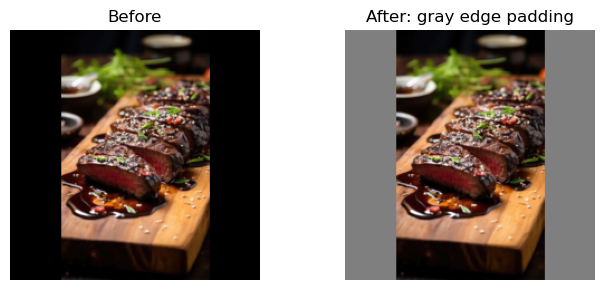

Sample modified: True


In [6]:
def grey_outer_padding(img):
    """Replace only complete black border rows/columns (not dark food pixels)."""
    out = np.array(img, copy=True)
    black = np.all(out == 0, axis=2)
    h, w = black.shape
    top = 0
    while top < h and black[top, :].all(): top += 1
    bottom = h
    while bottom > top and black[bottom-1, :].all(): bottom -= 1
    left = 0
    while left < w and black[:,left].all(): left += 1
    right = w
    while right > left and black[:,right-1].all(): right -= 1
    if top > 0: out[:top] = 127
    if bottom < h: out[bottom:] = 127
    if left > 0: out[:,:left] = 127
    if right < w: out[:,right:] = 127
    return out

# Sanity check the exact intervention before we measure its effect.
sample = np.array(X_test[shared_idx], copy=True)
changed_sample = grey_outer_padding(sample)
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].imshow(sample); ax[0].set_title("Before")
ax[1].imshow(changed_sample); ax[1].set_title("After: gray edge padding")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show(); plt.close(fig)
print("Sample modified:", bool(np.any(sample != changed_sample)))

In [7]:
# Tiny batches; no full in-memory copy of the altered test dataset.
# If this long cell is interrupted, earlier explanation outputs remain saved.
ABLATION_BATCH = 2
base_pred = preds_by_model[REFERENCE]
new_pred = np.empty(len(y_test), dtype=np.int32)
changed_count = 0
model = None
try:
    model = load_joined(REFERENCE)
    preprocessing = xai.find_preprocess_input(model.layers[0])
    for start in range(0, len(X_test), ABLATION_BATCH):
        original = np.asarray(X_test[start:start+ABLATION_BATCH])
        modified = np.stack([grey_outer_padding(im) for im in original])
        changed_count += int(np.any(original != modified, axis=(1,2,3)).sum())
        inputs = preprocessing(tf.convert_to_tensor(modified, dtype=tf.float32))
        probs = model(inputs, training=False).numpy()
        new_pred[start:start + len(probs)] = probs.argmax(axis=1)
        del original, modified, inputs, probs
        if start % 60 == 0:
            print(f"Checked {min(start+ABLATION_BATCH, len(X_test))}/{len(X_test)}", flush=True)
finally:
    del model
    release_model()

baseline = accuracy_score(y_test, base_pred)
ablated = accuracy_score(y_test, new_pred)
ablation = pd.DataFrame([{
    "model": REFERENCE,
    "test_images": len(y_test),
    "images_with_padding_changed": changed_count,
    "baseline_accuracy": baseline,
    "gray_padding_accuracy": ablated,
    "accuracy_change_percentage_points": (ablated-baseline)*100,
    "predictions_changed": int(np.count_nonzero(new_pred != base_pred)),
}])
display(ablation)
ablation.to_csv(MODELS_DIR / "P2_N4_padding_ablation.csv", index=False)
print("Saved ablation results to:", MODELS_DIR / "P2_N4_padding_ablation.csv")

Checked 2/314
Checked 62/314
Checked 122/314
Checked 182/314
Checked 242/314
Checked 302/314


,model,test_images,images_with_padding_changed,baseline_accuracy,gray_padding_accuracy,accuracy_change_percentage_points,predictions_changed
0,mobilenetv2,314,254,0.824841,0.83121,0.636943,13


Saved ablation results to: /Users/timhamilton/models/P2_N4_padding_ablation.csv


## 7. Discussion and deployment judgment

Notebook 3 showed that **ResNet50 reached 85.7% test accuracy**, while the larger EfficientNetV2M reached 85.4%. So bigger wasn't automatically better on this dataset. The explanation figures above help me judge whether the models are focused on the food itself, rather than just their final scores.

For the six examples, I would compare raw saliency to SmoothGrad and Grad-CAM: **do the strongest regions fall on the protein, or do they drift onto the surrounding plate and background?** Differences between the methods are worth investigating, not automatically evidence that one is wrong. The padding ablation above provides a concrete measurement for one suspected shortcut; I should interpret its actual accuracy change and count of changed predictions before claiming padding bias.

**My deployment call:** I'd treat this as a working classroom prototype, not a production-ready nutrition tool. These photos generally have one main protein source, and the model must still assign one of five labels even when the uploaded image is something else entirely. My first improvements would be more diverse photos, a stronger wrong-class/duplicate audit, and an out-of-distribution or abstention option in the app.

**After running:** In my presentation I'll point to one correct example, one mistake, and the measured padding ablation rather than pretending the maps tell the whole story. I will describe the visible heatmaps and the actual numeric ablation result instead of inventing a finding.

In [10]:
from pathlib import Path

home = Path.home()

for n in range(1, 5):
    matches = list(home.rglob(f"P2_Images-{n}_*.ipynb"))
    print(f"\nNOTEBOOK {n}")
    for path in matches:
        print(path)
    if not matches:
        print("NOT FOUND")


NOTEBOOK 1
/Users/timhamilton/P2_Images-1_Scrape_ProteinVision.ipynb
/Users/timhamilton/.ipynb_checkpoints/P2_Images-1_Scrape_ProteinVision-checkpoint.ipynb
/Users/timhamilton/Downloads/P2_Images-1_Scrape_ProteinVision.ipynb

NOTEBOOK 2
/Users/timhamilton/P2_Images-2_Preprocessing_ProteinVision.ipynb
/Users/timhamilton/.ipynb_checkpoints/P2_Images-2_Preprocessing_ProteinVision-checkpoint.ipynb
/Users/timhamilton/Downloads/P2_Images-2_Preprocessing_ProteinVision.ipynb
/Users/timhamilton/Downloads/P2_Images-2_Preprocessing_ProteinVision (1).ipynb

NOTEBOOK 3
/Users/timhamilton/P2_Images-3_TransferLearning_ProteinVision (1).ipynb
/Users/timhamilton/.ipynb_checkpoints/P2_Images-3_TransferLearning_ProteinVision (1)-checkpoint.ipynb
/Users/timhamilton/Downloads/P2_Images-3_TransferLearning_ProteinVision (1).ipynb
/Users/timhamilton/Downloads/P2_Images-3_TransferLearning_ProteinVision.ipynb

NOTEBOOK 4
/Users/timhamilton/P2_Images-4_xAI_ProteinVision_CPU_Friendly.ipynb
/Users/timhamilton/.ip